In [56]:
import numpy as np
import scipy
from scipy.stats import beta, boltzmann
from typing import Tuple
import sys
import os
import librosa
import matplotlib.pyplot as plt

project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
if project_root not in sys.path:
    sys.path.append(project_root)

from modules.Pyin import PitchExtractor
from util import audio

pitch_extractor = PitchExtractor()

[-2.9673258e-05 -3.6110661e-05 -3.8504204e-05 ... -3.0914794e-05
 -2.9738290e-05 -3.2249300e-05]


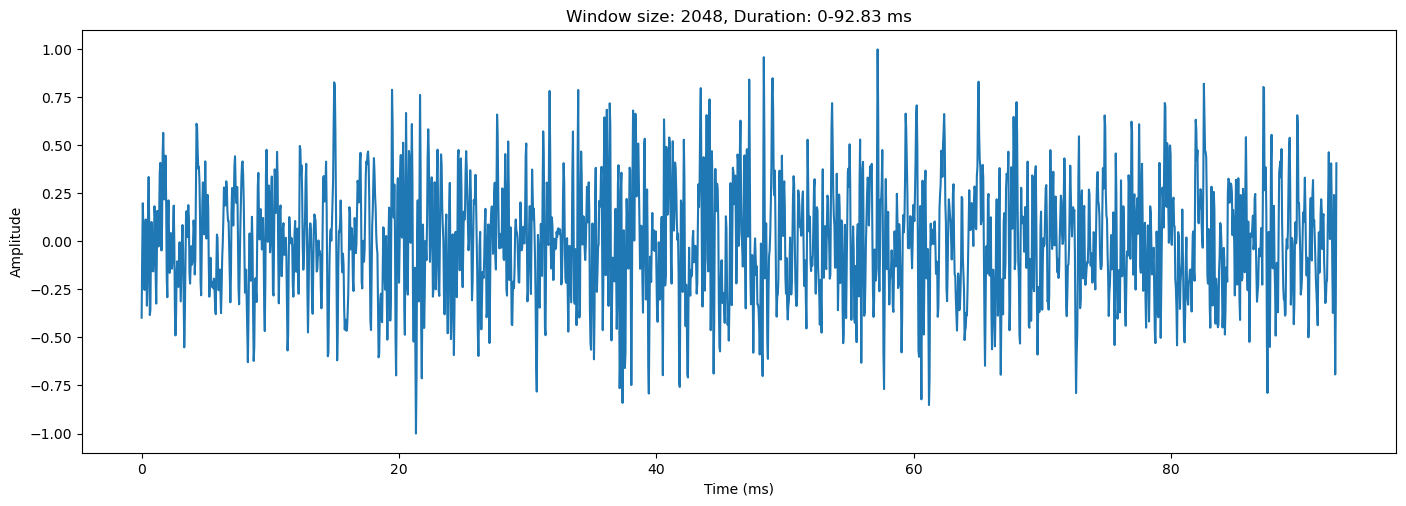

In [57]:
y, sr = librosa.load('./birds_of_feather.wav')
print(y)
windows_size = int(2048)
window_start = np.random.randint(0, len(y) - windows_size)
window_end = window_start + windows_size
window = y[window_start:window_end]
window = window / (np.max(np.abs(window)) + 1e-10) 

time_ms = np.arange(len(window)) * 1000 / sr

plt.figure(figsize=(14, 5))
plt.plot(time_ms, window)

plt.title(f'Window size: {windows_size}, Duration: 0-{time_ms[-1]:.2f} ms')
plt.xlabel('Time (ms)')
plt.ylabel('Amplitude')
plt.tight_layout(pad=0.5) # add padding to avoid overlap
plt.show()

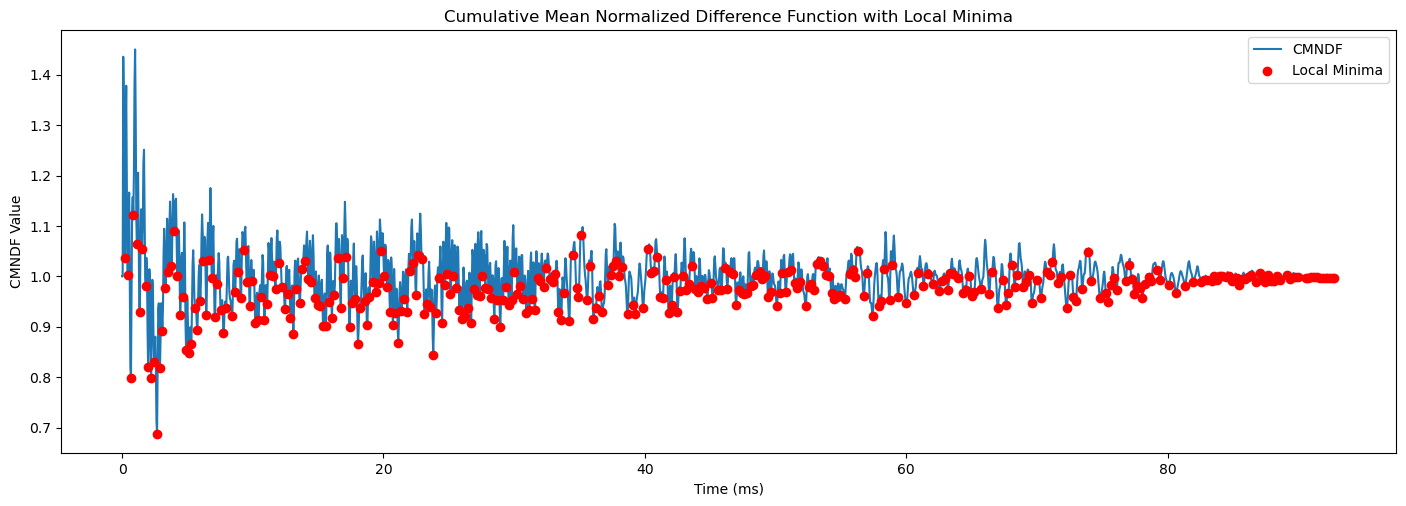

In [58]:
diff = pitch_extractor._difference_function(window)
cmndf = pitch_extractor._cumulative_mean_normalized_difference_function(diff)
local_minima, local_minima_index = pitch_extractor._find_local_minimas(cmndf)
plt.figure(figsize=(14, 5))
plt.plot(time_ms, cmndf, label='CMNDF')
plt.scatter(time_ms[local_minima_index], local_minima, color='red', label='Local Minima', zorder=5)
plt.title('Cumulative Mean Normalized Difference Function with Local Minima')
plt.xlabel('Time (ms)')
plt.ylabel('CMNDF Value')
plt.legend()
plt.tight_layout(pad=0.5)
plt.show()


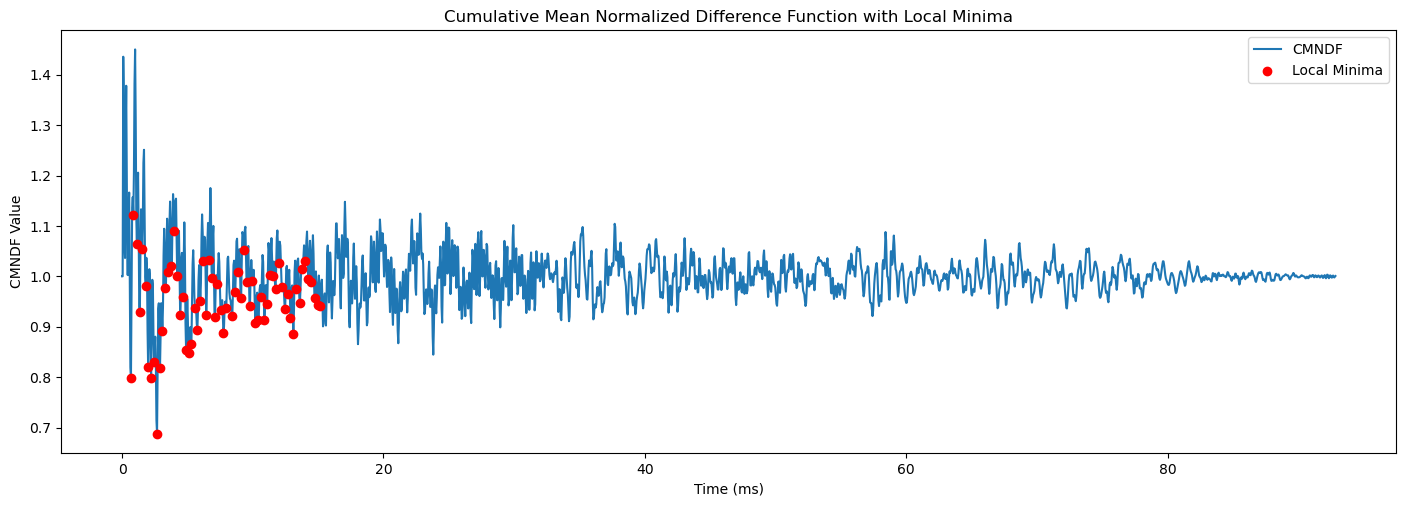

In [59]:
diff = pitch_extractor._difference_function(window)
cmndf = pitch_extractor._cumulative_mean_normalized_difference_function(diff)
local_minima, local_minima_index = pitch_extractor._find_local_minimas(cmndf)
filtered_local_minima, filtered_minima_index = pitch_extractor._filter_local_minimas(local_minima, local_minima_index)
plt.figure(figsize=(14, 5))
plt.plot(time_ms, cmndf, label='CMNDF')
plt.scatter(time_ms[filtered_minima_index], filtered_local_minima, color='red', label='Local Minima', zorder=5)
plt.title('Cumulative Mean Normalized Difference Function with Local Minima')
plt.xlabel('Time (ms)')
plt.ylabel('CMNDF Value')
plt.legend()
plt.tight_layout(pad=0.5)
plt.show()


[1470.         1160.52631579  882.          735.          648.52941176
  551.25        501.13636364  450.          408.33333333  373.72881356
  344.53125     324.26470588  302.05479452  282.69230769  265.6626506
  250.56818182  237.09677419  225.          214.0776699   204.16666667
  195.13274336  190.0862069   179.26829268  173.62204724  167.04545455
  160.94890511  155.28169014  150.          145.06578947  141.34615385
  137.8125      132.03592814  128.94736842  126.          119.18918919
  115.44502618  112.5         110.25        107.56097561  105.
  102.55813953  100.22727273   98.           95.86956522   93.82978723
   91.875        90.36885246   88.2          86.81102362   85.13513514
   83.52272727   81.66666667   80.18181818   78.75         77.64084507
   76.29757785   75.           73.5          72.53289474   71.3592233
   70.22292994   69.12225705   67.84615385   66.81818182   66.01796407]
1.0


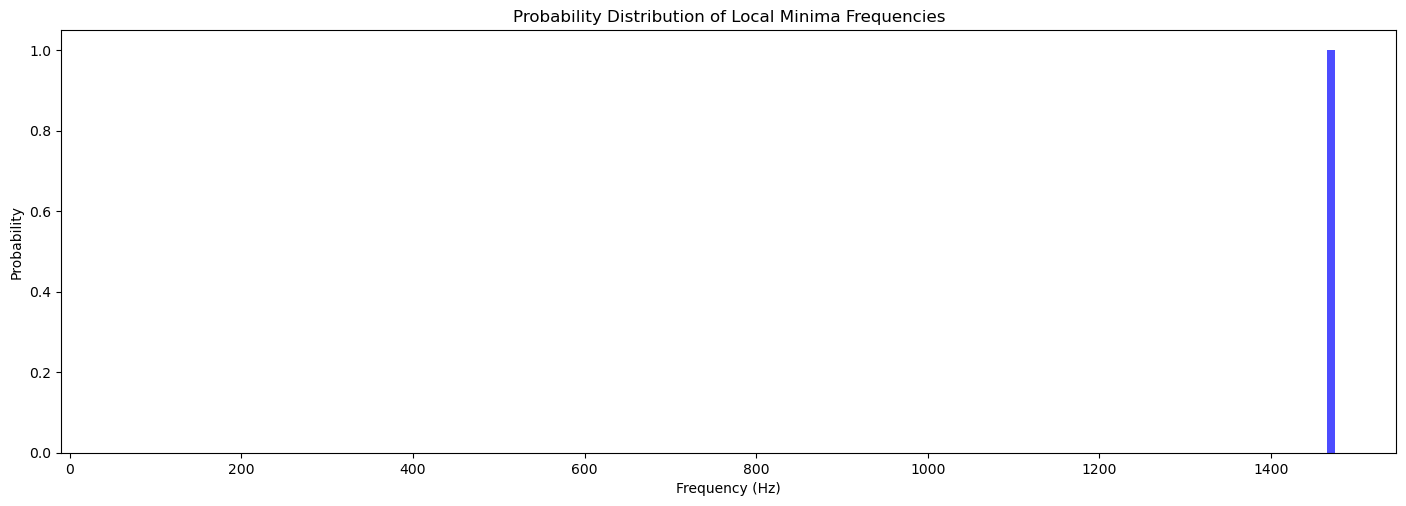

In [60]:
local_minima, local_minima_probs = pitch_extractor._frame_wise_pitch_extraction(window)
sr = pitch_extractor.sample_rate
local_minima_freqs = sr / filtered_minima_index
print(local_minima_freqs)
print(np.sum(local_minima_probs))

plt.figure(figsize=(14, 5))
plt.bar(local_minima_freqs, local_minima_probs, width=10, color='blue', alpha=0.7)
plt.title('Probability Distribution of Local Minima Frequencies')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Probability')
plt.tight_layout(pad=0.5)
plt.show()
